In [17]:
import pandas as pd
import numpy as np
from scipy import stats

file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (10194, 21)


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings("ignore")

# Load the existing Superstore dataset
file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [19]:
# Select numerical columns
numerical_columns = ["Sales", "Quantity", "Discount", "Profit"]

# Calculate descriptive statistics
print("DESCRIPTIVE STATISTICS")
display(df[numerical_columns].describe().T)

# Additional statistical measures
additional_stats = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Mode": df[numerical_columns].mode().iloc[0],
    "Variance": df[numerical_columns].var(),
    "Standard Deviation": df[numerical_columns].std(),
    "Skewness": df[numerical_columns].skew(),
    "Kurtosis": df[numerical_columns].kurt()
})

display(additional_stats.round(3))

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
Sales,10194.0,228.225854,619.906839,0.444,17.2200,53.91,209.500000,22638.480
Quantity,10194.0,3.791838,2.228317,1.000,2.0000,3.00,5.000000,14.000
Discount,10194.0,0.155385,0.206249,0.000,0.0000,0.20,0.200000,0.800
Profit,10194.0,28.673417,232.465115,-6599.978,1.7608,8.69,29.297925,8399.976


,Mean,Median,Mode,Variance,Standard Deviation,Skewness,Kurtosis
Sales,228.226,53.91,12.96,384284.489,619.907,12.984,306.366
Quantity,3.792,3.00,2.00,4.965,2.228,1.269,1.962
Discount,0.155,0.20,0.00,0.043,0.206,1.687,2.416
Profit,28.673,8.69,0.00,54040.030,232.465,7.605,401.693


In [20]:
from scipy import stats
import numpy as np

sales = df["Sales"].dropna()

n = len(sales)
mean_sales = sales.mean()
standard_error = sales.std(ddof=1) / np.sqrt(n)

lower, upper = stats.t.interval(
    0.95,
    df=n - 1,
    loc=mean_sales,
    scale=standard_error
)

print("Number of observations:", n)
print(f"Mean Sales: {mean_sales:.2f}")
print(f"95% Confidence Interval: ({lower:.2f}, {upper:.2f})")

Number of observations: 10194
Mean Sales: 228.23
95% Confidence Interval: (216.19, 240.26)


### Confidence Interval Interpretation

The mean sales value is **228.23**, and the 95% confidence interval ranges from **216.19 to 240.26**. This means that, under the assumptions of the method, the interval provides a plausible range for the population's true average sales.

**Business implication:** The company can use this estimate to understand its average sales performance, while remembering that individual transactions may vary considerably.

In [21]:
# Separate profit values by discount status
no_discount = df.loc[df["Discount"] == 0, "Profit"].dropna()
with_discount = df.loc[df["Discount"] > 0, "Profit"].dropna()

# Welch's independent-samples t-test
t_stat, p_value = stats.ttest_ind(
    no_discount,
    with_discount,
    equal_var=False
)

print("HYPOTHESIS TEST: DISCOUNT AND PROFIT")
print("No-discount transactions:", len(no_discount))
print("Discounted transactions:", len(with_discount))
print("Mean profit without discount:", round(no_discount.mean(), 2))
print("Mean profit with discount:", round(with_discount.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Conclusion: Reject the null hypothesis.")
    print("The mean profits differ significantly between the two groups.")
else:
    print("Conclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in mean profits.")

HYPOTHESIS TEST: DISCOUNT AND PROFIT
No-discount transactions: 4925
Discounted transactions: 5269
Mean profit without discount: 66.34
Mean profit with discount: -6.53
T-statistic: 15.8941
P-value: 3.7270202073140507e-56
Conclusion: Reject the null hypothesis.
The mean profits differ significantly between the two groups.


MONTHLY SALES TIME SERIES
Number of months: 48


Order Date
2023-01-01    14518.055
2023-02-01     4519.892
2023-03-01    56933.909
2023-04-01    28295.345
2023-05-01    26319.767
Freq: MS, Name: Sales, dtype: float64

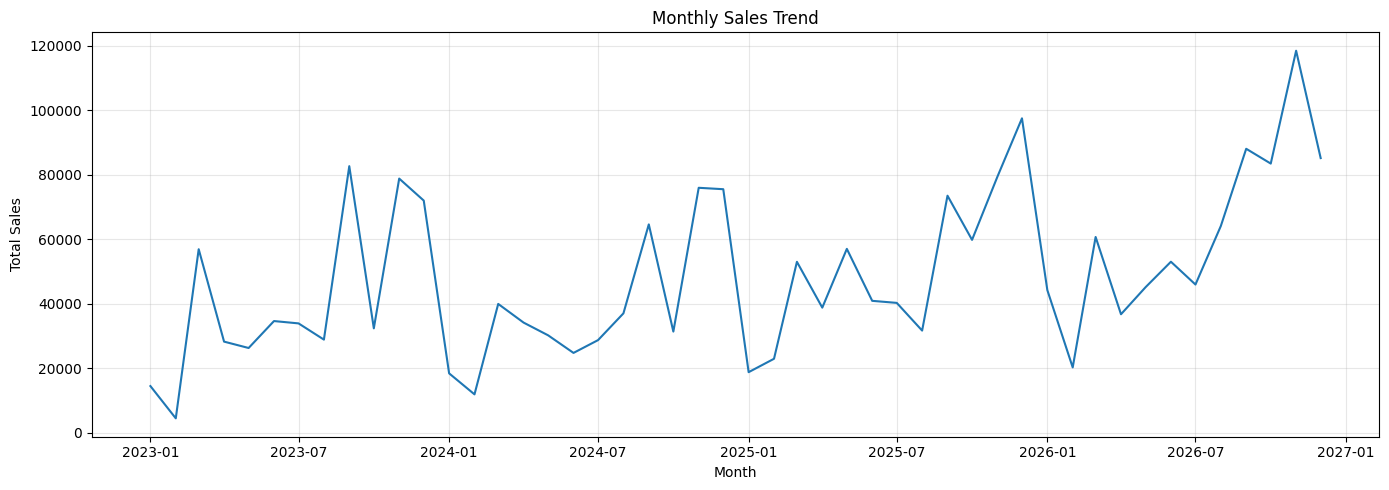

In [22]:
# Convert Order Date to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Create monthly sales time series
monthly_sales = (
    df.set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
)

print("MONTHLY SALES TIME SERIES")
print("Number of months:", len(monthly_sales))
display(monthly_sales.head())

# Plot monthly sales
plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

TIME-SERIES SUMMARY
Number of months: 48
Start date: 2023-01-01
End date: 2026-12-01
Total sales: 2326534.35

First 5 months:


Order Date
2023-01-01    14518.055
2023-02-01     4519.892
2023-03-01    56933.909
2023-04-01    28295.345
2023-05-01    26319.767
Freq: MS, Name: Sales, dtype: float64

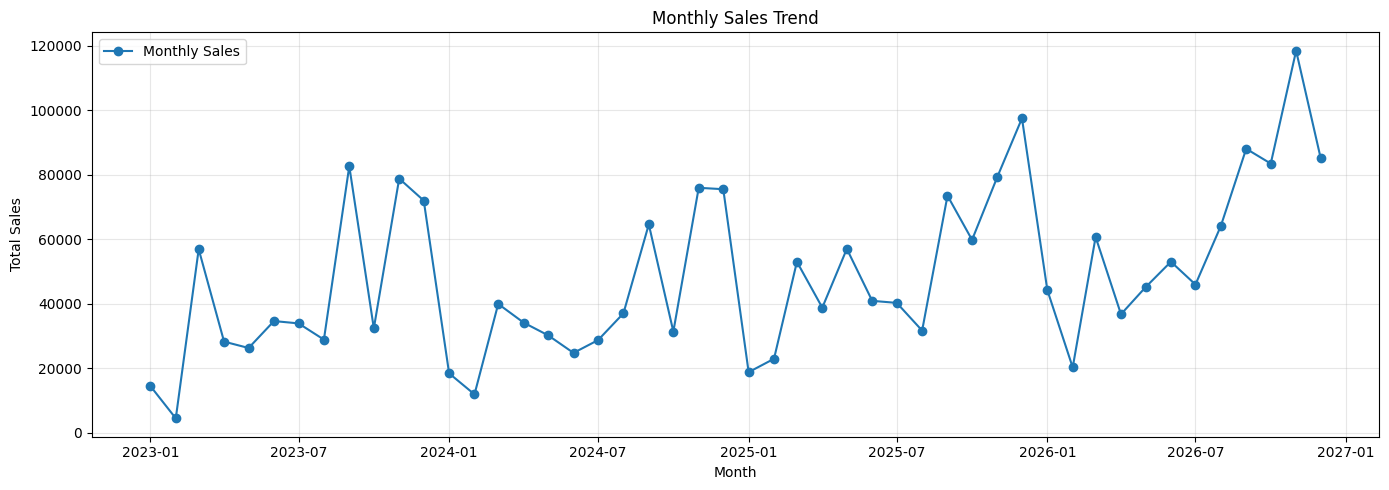

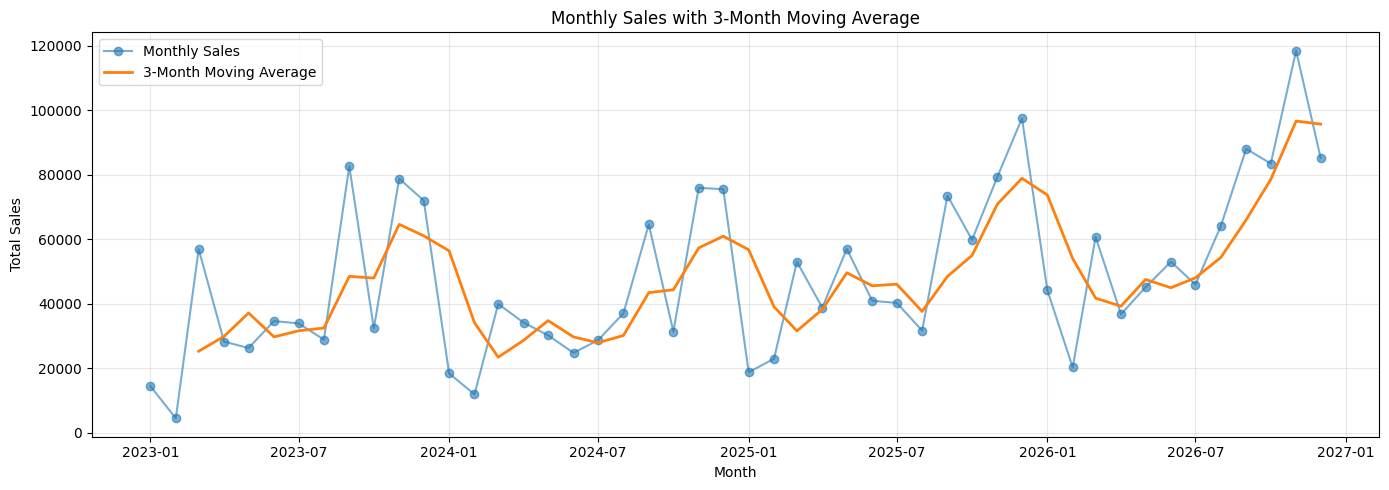

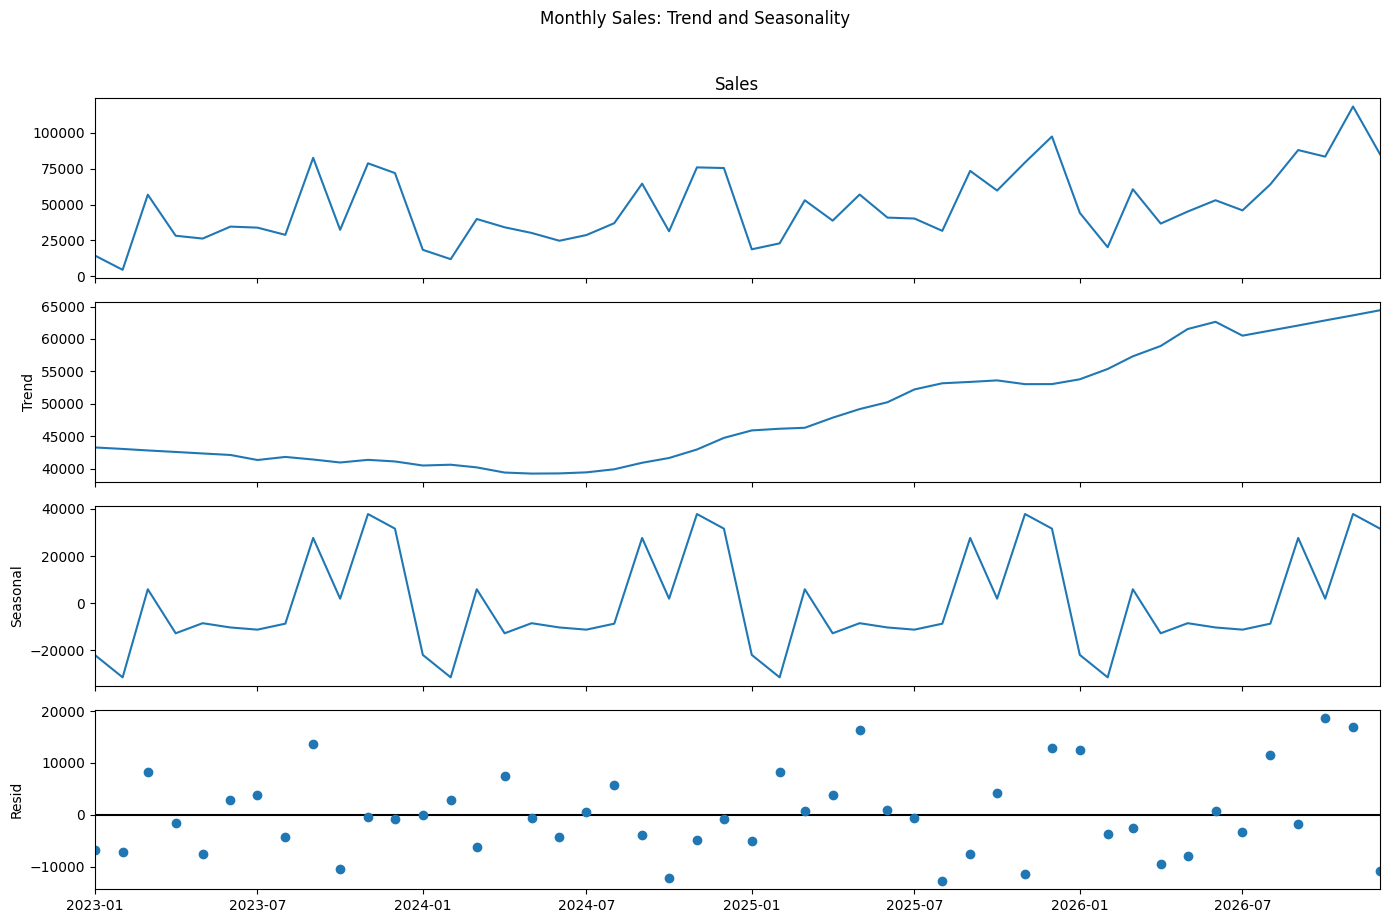


ADF STATIONARITY TEST
ADF statistic: -4.4375
P-value: 0.000255
Critical value (5%): -2.9253
Conclusion: Reject the null hypothesis of a unit root.
The series appears stationary according to the ADF test.

BUSINESS INTERPRETATION
The monthly sales chart shows how sales change over time.
The 3-month moving average smooths short-term fluctuations.
Seasonal decomposition separates the estimated trend,
seasonal pattern, and residual variation.
The ADF test helps assess stationarity and whether
differencing may be needed for forecasting models.


In [23]:

# TASK 4: TIME-SERIES ANALYSIS
# Trend, seasonality, residuals, stationarity, and moving average smoothing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")

# 1. Prepare the date and sales columns
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# 2. Calculate monthly sales
monthly_sales = (
    df.dropna(subset=["Order Date", "Sales"])
      .set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
      .asfreq("MS")
)

# Fill any missing months, if present
monthly_sales = monthly_sales.fillna(0)

print("TIME-SERIES SUMMARY")
print("Number of months:", len(monthly_sales))
print("Start date:", monthly_sales.index.min().date())
print("End date:", monthly_sales.index.max().date())
print("Total sales:", round(monthly_sales.sum(), 2))

print("\nFirst 5 months:")
display(monthly_sales.head())

# 3. Plot monthly sales
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    label="Monthly Sales"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Moving Average Smoothing (3-month window)
moving_average = monthly_sales.rolling(window=3).mean()

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    alpha=0.6,
    label="Monthly Sales"
)
plt.plot(
    moving_average.index,
    moving_average.values,
    linewidth=2,
    label="3-Month Moving Average"
)
plt.title("Monthly Sales with 3-Month Moving Average")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Decompose sales into trend, seasonality, and residuals
if len(monthly_sales) >= 24:
    decomposition = seasonal_decompose(
        monthly_sales,
        model="additive",
        period=12,
        extrapolate_trend="freq"
    )

    decomposition.plot()
    plt.gcf().set_size_inches(14, 9)
    plt.suptitle("Monthly Sales: Trend and Seasonality", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print(
        "At least 24 months are recommended "
        "for yearly seasonal decomposition."
    )

# 6. Augmented Dickey-Fuller (ADF) stationarity test
adf_result = adfuller(monthly_sales.dropna(), autolag="AIC")

adf_statistic = adf_result[0]
p_value = adf_result[1]
critical_value_5 = adf_result[4]["5%"]

print("\nADF STATIONARITY TEST")
print("ADF statistic:", round(adf_statistic, 4))
print("P-value:", round(p_value, 6))
print("Critical value (5%):", round(critical_value_5, 4))

if p_value < 0.05:
    print("Conclusion: Reject the null hypothesis of a unit root.")
    print("The series appears stationary according to the ADF test.")
else:
    print("Conclusion: Fail to reject the null hypothesis of a unit root.")
    print("The series may be non-stationary.")

# 7. Business interpretation
print("\nBUSINESS INTERPRETATION")
print("The monthly sales chart shows how sales change over time.")
print("The 3-month moving average smooths short-term fluctuations.")
print("Seasonal decomposition separates the estimated trend,")
print("seasonal pattern, and residual variation.")
print("The ADF test helps assess stationarity and whether")
print("differencing may be needed for forecasting models.")


In [24]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Load the Superstore dataset again
file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


FORECAST EVALUATION
MAE: 11752.42
RMSE: 13071.68
MAPE: 22.52 %


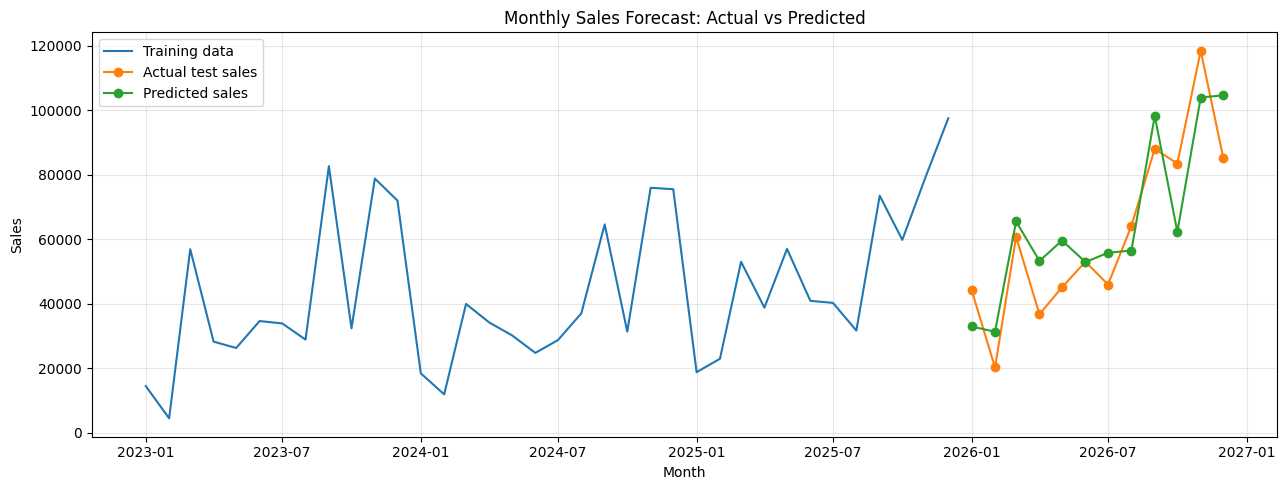

NEXT 6 MONTHS FORECAST


,Forecast Sales
2027-01-01,51138.83
2027-02-01,43083.85
2027-03-01,77514.46
2027-04-01,62984.26
2027-05-01,70407.56
2027-06-01,67041.04


In [26]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the last 12 months as test data
train = monthly_sales.iloc[:-12]
test = monthly_sales.iloc[-12:]

# Fit a trend and yearly seasonal pattern
model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

fitted_model = model.fit()
predictions = fitted_model.forecast(len(test))

# Evaluate forecast accuracy
mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))

# Avoid division by zero when calculating MAPE
nonzero = test != 0
mape = (
    np.mean(np.abs((test[nonzero] - predictions[nonzero]) / test[nonzero]))
    * 100
)

print("FORECAST EVALUATION")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

# Plot actual vs predicted sales
plt.figure(figsize=(13, 5))
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test sales", marker="o")
plt.plot(predictions.index, predictions, label="Predicted sales", marker="o")
plt.title("Monthly Sales Forecast: Actual vs Predicted")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Refit using all available data and forecast the next 6 months
final_model = ExponentialSmoothing(
    monthly_sales,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

future_forecast = final_model.forecast(6)

print("NEXT 6 MONTHS FORECAST")
display(future_forecast.rename("Forecast Sales").to_frame().round(2))

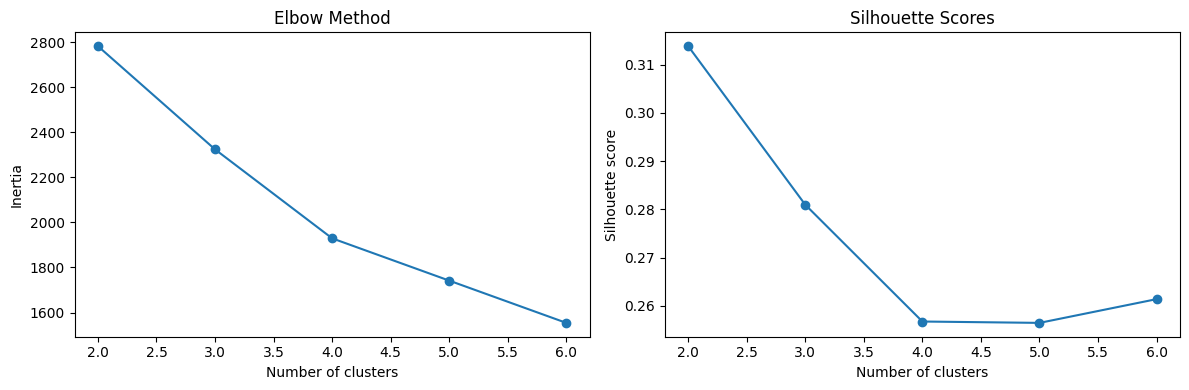

Silhouette scores:
k=2: 0.314
k=3: 0.281
k=4: 0.257
k=5: 0.256
k=6: 0.261


,Customer_Count,Average_Sales,Average_Profit,Average_Quantity,Average_Discount,Average_Orders
Cluster,,,,,,
0,202,1551.19,-96.28,32.09,0.26,4.69
1,264,3712.55,367.00,69.67,0.16,8.81
2,55,9717.80,2281.43,81.24,0.12,8.62
3,283,1761.84,315.83,32.89,0.09,4.84


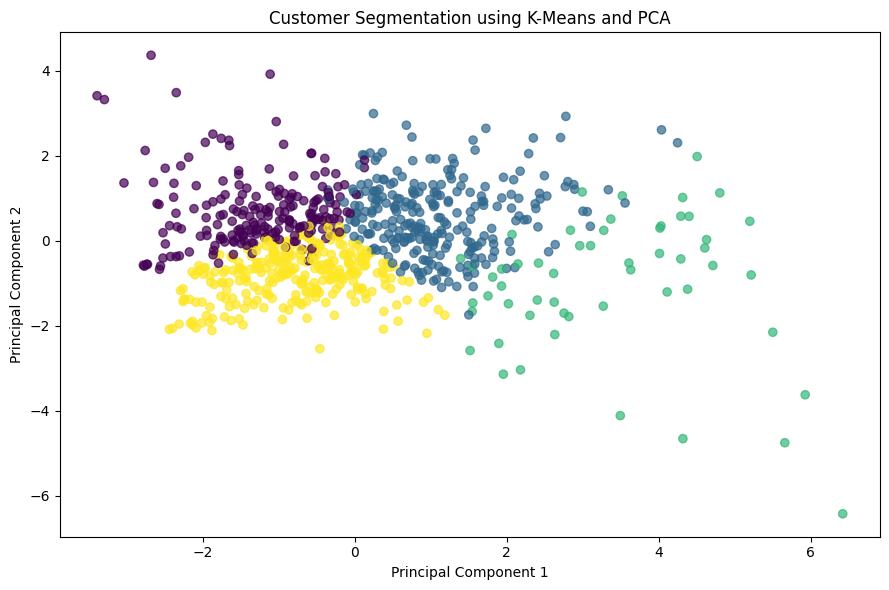

Variance explained by the two PCA components: 73.36 %


In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Aggregate transactions into one row per customer
customer_data = df.groupby("Customer ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean"),
    Number_of_Orders=("Order ID", "nunique")
).reset_index()

features = [
    "Total_Sales",
    "Total_Profit",
    "Total_Quantity",
    "Average_Discount",
    "Number_of_Orders"
]

# Standardize features so larger scales do not dominate
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_data[features])

# Compare cluster counts using inertia and silhouette score
inertias = []
silhouette_scores = []
k_values = range(2, 7)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.title("Silhouette Scores")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")

plt.tight_layout()
plt.show()

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: {score:.3f}")

# Use 4 clusters as an initial model
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

# Summarize the customer groups
cluster_summary = customer_data.groupby("Cluster").agg(
    Customer_Count=("Customer ID", "count"),
    Average_Sales=("Total_Sales", "mean"),
    Average_Profit=("Total_Profit", "mean"),
    Average_Quantity=("Total_Quantity", "mean"),
    Average_Discount=("Average_Discount", "mean"),
    Average_Orders=("Number_of_Orders", "mean")
).round(2)

display(cluster_summary)

# Visualize clusters in two dimensions using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=customer_data["Cluster"],
    cmap="viridis",
    alpha=0.7
)
plt.title("Customer Segmentation using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print(
    "Variance explained by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

,Model,MAE,RMSE,R2
0,Linear Regression,61.709,214.026,0.489
1,Decision Tree,28.787,120.929,0.837


Top 10 important features:


,Importance
Sales,0.604109
Discount,0.275223
Sub-Category_Supplies,0.034778
Region_East,0.027072
Region_South,0.013911
Sub-Category_Binders,0.009888
Segment_Corporate,0.009692
Sub-Category_Machines,0.007568
Quantity,0.006009
Sub-Category_Copiers,0.004532


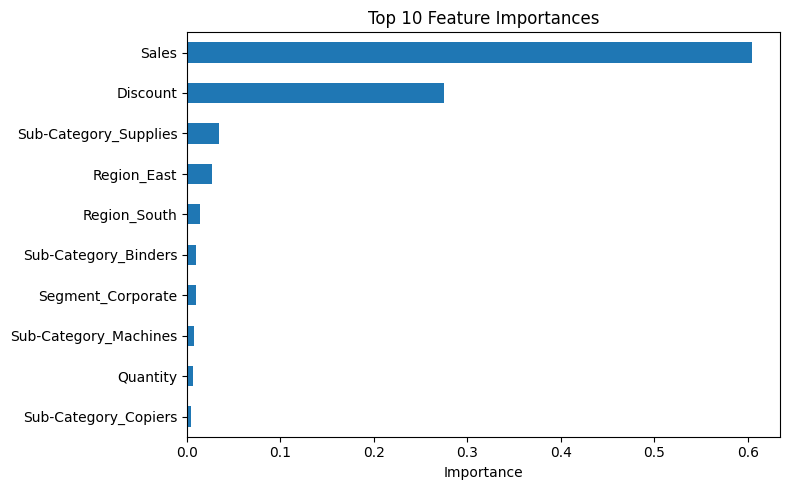

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare prediction dataset
model_df = df[
    ["Sales", "Quantity", "Discount", "Profit", "Ship Mode",
     "Segment", "Category", "Sub-Category", "Region"]
].dropna().copy()

# Convert categorical features into numeric columns
X = pd.get_dummies(
    model_df.drop(columns="Profit"),
    drop_first=True
)
y = model_df["Profit"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train two regression models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=8, random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).round(3)
display(results_df)

# Feature importance from the Decision Tree
tree_model = models["Decision Tree"]
importance = pd.Series(
    tree_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 important features:")
display(importance.head(10).to_frame("Importance"))

importance.head(10).sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Feature Importances"
)
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [29]:
# Task 4: Chi-Square Test
import pandas as pd
from scipy.stats import chi2_contingency

# Step 1: Load the dataset
file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Step 2: Create a contingency table
contingency_table = pd.crosstab(
    df["Segment"],
    df["Region"]
)

print("\nContingency Table:")
print(contingency_table)

# Step 3: Perform the chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Step 4: Display the results
print("\nChi-Square Test Results")
print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

# Step 5: Interpret the results
alpha = 0.05

if p_value < alpha:
    print(
        "\nConclusion: Customer Segment and Region "
        "are significantly associated."
    )
else:
    print(
        "\nConclusion: No statistically significant "
        "association was found between Customer Segment and Region."
    )

Dataset loaded successfully!
Dataset shape: (10194, 21)

Contingency Table:
Region       Central  East  South  West
Segment                                
Consumer        1224  1529    838  1690
Corporate        673   933    510   974
Home Office      438   524    272   589

Chi-Square Test Results
Chi-square statistic: 6.1988
Degrees of freedom: 6
P-value: 0.40129328870654657

Conclusion: No statistically significant association was found between Customer Segment and Region.


### Chi-Square Test Interpretation

The chi-square test was performed to examine the association between Customer Segment and Region. The chi-square statistic was 6.1988, with 6 degrees of freedom and a p-value of 0.4013.

Since the p-value is greater than 0.05, we fail to reject the null hypothesis. There is insufficient statistical evidence of an association between Customer Segment and Region in this dataset.

**Business implication:** Based on this test, there is no statistically significant evidence that customer segment distribution differs by region. The company can continue analyzing regional sales and customer behavior to identify other useful business patterns.

In [30]:
# Task 4: One-Way ANOVA Test
import pandas as pd
from scipy.stats import f_oneway

# Load dataset
file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

# Group profit by customer segment
segment_profits = [
    group["Profit"].dropna()
    for _, group in df.groupby("Segment")
]

# Perform ANOVA
f_statistic, p_value = f_oneway(*segment_profits)

# Display results
print("ANOVA F-statistic:", round(f_statistic, 4))
print("P-value:", p_value)

# Interpret results
if p_value < 0.05:
    print("Conclusion: At least one customer segment has a significantly different mean profit.")
else:
    print("Conclusion: No statistically significant difference in mean profit was found.")

ANOVA F-statistic: 0.9414
P-value: 0.3901265275749747
Conclusion: No statistically significant difference in mean profit was found.


### ANOVA Test Interpretation

A one-way ANOVA test was performed to determine whether mean Profit differs across the three customer segments: Consumer, Corporate, and Home Office.

The F-statistic was 0.9414, and the p-value was 0.3901. Since the p-value is greater than 0.05, we fail to reject the null hypothesis. The analysis does not provide sufficient statistical evidence that mean Profit differs across the customer segments.

**Business implication:** The company should not assume that one customer segment is more profitable than another based on this test alone. Further analysis of sales, discounts, product categories, and costs may help identify profitability opportunities.


ARIMA Results
MAE: 23717.82
RMSE: 27320.37
MAPE: 53.96%

SARIMA Results
MAE: 13642.80
RMSE: 15996.53
MAPE: 26.61%


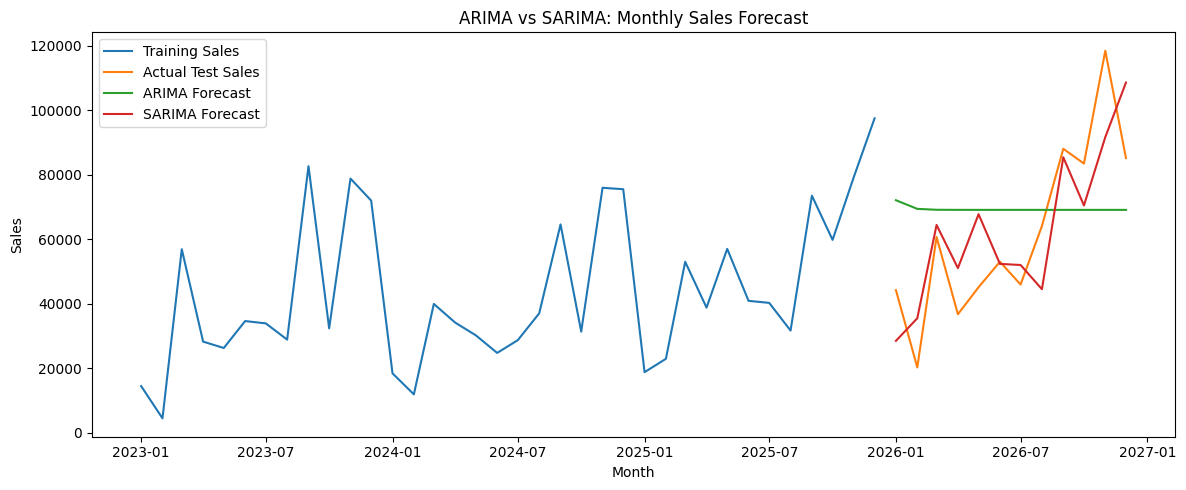


Next 6 Months SARIMA Forecast
2027-01-01    28535.88
2027-02-01    35534.37
2027-03-01    64453.98
2027-04-01    51077.52
2027-05-01    67785.90
2027-06-01    52388.09
Freq: MS, Name: predicted_mean, dtype: float64


In [31]:
# Task 4: ARIMA and SARIMA Forecasting

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

warnings.filterwarnings("ignore")

# Step 1: Load and prepare monthly sales data
file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

df["Order Date"] = pd.to_datetime(df["Order Date"])

monthly_sales = (
    df.set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
      .asfreq("MS")
      .fillna(0)
)

# Step 2: Split data (last 12 months for testing)
train = monthly_sales.iloc[:-12]
test = monthly_sales.iloc[-12:]

# Step 3: Fit ARIMA model
arima_model = ARIMA(train, order=(1, 1, 1))
arima_fit = arima_model.fit()
arima_pred = arima_fit.forecast(steps=len(test))
arima_pred.index = test.index

# Step 4: Fit seasonal ARIMA (SARIMA) model
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)
sarima_pred = sarima_fit.forecast(steps=len(test))
sarima_pred.index = test.index

# Step 5: Evaluate both models
def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = actual != 0
    mape = (
        np.mean(np.abs(
            (actual[nonzero] - predicted[nonzero])
            / actual[nonzero]
        )) * 100
        if nonzero.any() else np.nan
    )
    return mae, rmse, mape

for name, predictions in [
    ("ARIMA", arima_pred),
    ("SARIMA", sarima_pred)
]:
    mae, rmse, mape = evaluate_forecast(test, predictions)
    print(f"\n{name} Results")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAPE: {mape:.2f}%")

# Step 6: Plot actual and predicted sales
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Training Sales")
plt.plot(test.index, test, label="Actual Test Sales")
plt.plot(arima_pred.index, arima_pred, label="ARIMA Forecast")
plt.plot(sarima_pred.index, sarima_pred, label="SARIMA Forecast")
plt.title("ARIMA vs SARIMA: Monthly Sales Forecast")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

# Step 7: Forecast the next 6 months using SARIMA
future_forecast = sarima_fit.forecast(steps=6)
future_forecast.index = pd.date_range(
    start=monthly_sales.index[-1] + pd.offsets.MonthBegin(1),
    periods=6,
    freq="MS"
)

print("\nNext 6 Months SARIMA Forecast")
print(future_forecast.round(2))

### ARIMA and SARIMA Forecasting — Interpretation

ARIMA and SARIMA models were used to forecast monthly sales and evaluated using the last 12 months of data as the test set.

ARIMA achieved an MAE of 23,717.82, RMSE of 27,320.37, and MAPE of 53.96%. SARIMA performed better, achieving an MAE of 13,642.80, RMSE of 15,996.53, and MAPE of 26.61%.

The SARIMA model captured seasonal patterns more effectively than ARIMA in this evaluation. However, its forecast errors indicate that predictions are not exact and should be interpreted with caution.

**Business implication:** SARIMA can support sales planning and inventory decisions, but forecasts should be reviewed alongside actual sales and updated as new data becomes available.

In [32]:
# Task 4: Logistic Regression Classification

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Step 1: Load the dataset
file_path = "../data/raw/sample_-_superstore.xls"
df = pd.read_excel(file_path)

print("Dataset loaded:", df.shape)

# Step 2: Create a binary target
profit_median = df["Profit"].median()

df["High_Profit"] = (
    df["Profit"] > profit_median
).astype(int)

print("Median Profit:", round(profit_median, 2))
print("\nTarget distribution:")
print(df["High_Profit"].value_counts())

# Step 3: Select features
numeric_features = ["Sales", "Quantity", "Discount"]
categorical_features = [
    "Ship Mode", "Segment", "Category",
    "Sub-Category", "Region"
]

X = df[numeric_features + categorical_features]
y = df["High_Profit"]

# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 5: Prepare numeric and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Step 6: Build and train Logistic Regression
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

# Step 7: Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Step 8: Evaluate the model
print("\nLogistic Regression Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["At or Below Median Profit", "Above Median Profit"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Dataset loaded: (10194, 21)
Median Profit: 8.69

Target distribution:
High_Profit
0    5098
1    5096
Name: count, dtype: int64

Logistic Regression Results
Accuracy: 0.797
Precision: 0.7911
Recall: 0.8067
F1-score: 0.7988
ROC-AUC: 0.8833

Classification Report:
                           precision    recall  f1-score   support

At or Below Median Profit       0.80      0.79      0.80      1020
      Above Median Profit       0.79      0.81      0.80      1019

                 accuracy                           0.80      2039
                macro avg       0.80      0.80      0.80      2039
             weighted avg       0.80      0.80      0.80      2039

Confusion Matrix:
[[803 217]
 [197 822]]


### Logistic Regression — Interpretation

Logistic Regression was used to classify Superstore transactions into two categories: above-median profit and at-or-below-median profit. The median profit was 8.69, and the dataset contained nearly equal numbers of transactions in both classes.

The model achieved **79.70% accuracy**, **79.11% precision**, **80.67% recall**, an **F1-score of 79.88%**, and a **ROC-AUC of 0.8833** on the test set.

The confusion matrix showed 803 correctly classified transactions at or below median profit and 822 correctly classified above-median-profit transactions.

**Business implication:** This model demonstrates how transaction details can help identify transactions likely to generate above-median profit. Further validation is required before using the model for business decisions.

**Limitation:** Above-median profit is a constructed classification target, not customer churn. The results do not establish causation and may vary with different data splits.

# Task 4: Advanced Analytics and Statistical Modeling — Conclusion

## 1. Descriptive Statistics

Calculated mean, median, mode, variance, standard deviation, skewness, and kurtosis for Sales, Quantity, Discount, and Profit. Sales and Profit showed strong right-skewness, indicating the presence of unusually large transactions. The 95% confidence interval for mean Sales was **216.19 to 240.26**, with a sample mean of 228.23.

## 2. Hypothesis Testing and Statistical Analysis

An independent-samples Welch's t-test compared profit on discounted and non-discounted transactions. The p-value was approximately **3.73 × 10⁻⁵⁶**, indicating a statistically significant difference in mean profit between the two groups.

The chi-square test between customer Segment and Region returned a p-value of **0.4013**, showing no statistically significant association between these variables. One-way ANOVA comparing profit across customer segments returned a p-value of **0.3901**, providing insufficient evidence of a difference in mean profit across the segments.

These results indicate statistical associations or differences, where present, and do not establish causation.

## 3. Time-Series Analysis and Forecasting

Analyzed **48 months of sales data**, from January 2023 to December 2026, with total sales of 2,326,534.35. Decomposed the monthly sales series into trend, seasonal, and residual components and applied a three-month moving average to smooth short-term fluctuations.

The Augmented Dickey-Fuller (ADF) test returned a p-value of **0.000255**, providing evidence against the presence of a unit root in the monthly sales series.

Forecasting models were evaluated using a 12-month holdout period:

- **Exponential Smoothing:** MAE = 11,752.42, RMSE = 13,071.68, MAPE = 22.52%.
- **ARIMA:** MAE = 23,717.82, RMSE = 27,320.37, MAPE = 53.96%.
- **SARIMA:** MAE = 13,642.80, RMSE = 15,996.53, MAPE = 26.61%.

Exponential Smoothing achieved the lowest errors among the three models on this evaluation period. A six-month sales forecast was generated for January–June 2027, with total forecast sales of **372,170.00**. These values are predictions, not actual future sales.

## 4. Customer Segmentation

Applied StandardScaler and K-Means clustering to group **804 customers** using total sales, total profit, total quantity, average discount, and number of orders.

The best silhouette score among the tested cluster counts was **0.314 at k = 2**. A four-cluster solution was also examined to provide more detailed exploratory customer segments. The clusters highlighted differences in customer value, profitability, purchase volume, and discount usage.

Business recommendations included retaining high-value customers, encouraging repeat purchases, increasing order value among profitable lower-spending customers, and reviewing discounting and costs for loss-making customers.

The four-cluster solution should be treated as exploratory because the two-cluster solution achieved the highest silhouette score among the tested values.

## 5. Predictive Modeling — Regression

Compared Linear Regression and Decision Tree Regression to predict Profit using transaction and categorical features.

- **Linear Regression:** MAE = 61.709, RMSE = 214.026, R² = 0.489.
- **Decision Tree Regression:** MAE = 28.787, RMSE = 120.929, R² = 0.837.

The Decision Tree model performed better on the held-out test set, producing lower prediction errors and a higher R² score. Sales and Discount were its two most important features according to the model's feature-importance scores.

Feature importance indicates predictive contribution within the fitted model; it does not establish a causal relationship.

## 6. Predictive Modeling — Classification

Applied Logistic Regression to classify transactions into two categories: **High Profit** (Profit greater than the median profit of 8.69) and not High Profit.

The model achieved the following test-set metrics:

- Accuracy: **79.7%**
- Precision: **79.11%**
- Recall: **80.67%**
- F1-score: **79.88%**
- ROC-AUC: **0.8833**

These results indicate that the model was able to distinguish between the two profit categories on the held-out test set. This is a high-profit classification task, not a customer churn prediction task.

## 7. Limitations

- Results depend on the quality and characteristics of the available dataset.
- Statistical significance does not establish causation.
- Forecasts are estimates and may not reflect actual future sales.
- The ADF test result does not guarantee that every forecasting model will perform well.
- Customer clusters depend on the selected features, scaling method, and number of clusters.
- Predictive metrics come from a particular train/test split and may change with different splits.
- Feature importance does not imply that a feature causes changes in profit.
- Classification results apply to the defined high-profit target and should not be interpreted as churn prediction.

## 8. Conclusion

This project applied descriptive and inferential statistics, confidence intervals, hypothesis testing, time-series decomposition, stationarity testing, moving-average smoothing, forecasting, customer segmentation, regression, and classification to the Sample Superstore dataset.

The analysis identified differences in profitability between discounted and non-discounted transactions, explored customer segments, evaluated sales forecasting models, and compared predictive models for profit estimation and classification. The findings demonstrate how data analytics can support sales planning, customer targeting, and profitability analysis while highlighting the importance of validation, careful interpretation, and awareness of model limitations.